# 4. Ablation Study

This notebook investigates the effects of loss functions, image
resolution, and data augmentation on mammography classification.

Controlled experiments are conducted using an ImageNet-pretrained
ResNet50 classifier with fixed data partitions and training settings.
Only one primary experimental factor is modified at a time.

## 4.1 Data and Experimental Setup

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

In [3]:
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_DIR = PROJECT_DIR / "data"
SPLIT_DIR = DATA_DIR / "splits"

MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results" / "ablation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Project:", PROJECT_DIR)

Device: cuda
Project: c:\Users\Admin\Desktop\Projects\5_sem\DeepLearning\lab4


In [4]:
train_df = pd.read_csv(SPLIT_DIR / "train_pairs.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_pairs.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_pairs.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 1352
Validation: 1150
Test: 1907


In [5]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print(df["target"].value_counts())


Train
target
0    1014
1     338
Name: count, dtype: int64

Validation
target
0    1093
1      57
Name: count, dtype: int64

Test
target
0    1808
1      99
Name: count, dtype: int64


In [6]:
train_ids = set(train_df["study_id"])
val_ids = set(val_df["study_id"])
test_ids = set(test_df["study_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("No study-level leakage detected.")

No study-level leakage detected.


The prepared study-level partitions are reused without modification.
Class imbalance is retained, and no study identifiers overlap across
training, validation, and test sets.

## 4.2 Loss Function Ablation

In [7]:
class ResizeWithPadding:
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        image = image.copy()

        image.thumbnail(
            (self.size, self.size),
            Image.Resampling.BILINEAR
        )

        width, height = image.size

        padding = (
            (self.size - width) // 2,
            (self.size - height) // 2,
            self.size - width - (self.size - width) // 2,
            self.size - height - (self.size - height) // 2
        )

        return TF.pad(image, padding, fill=0)

In [8]:
IMAGE_SIZE = 224

image_transform = transforms.Compose([
    ResizeWithPadding(IMAGE_SIZE),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [9]:
class MammographyDataset(Dataset):

    def __init__(self, dataframe, view="CC", transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.view = view
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = row[f"{self.view}_path"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            row["target"],
            dtype=torch.float32
        )

        return image, label

In [10]:
BATCH_SIZE = 8
EPOCHS = 10
LEARNING_RATE = 1e-4

train_dataset = MammographyDataset(
    train_df, view="CC", transform=image_transform
)

val_dataset = MammographyDataset(
    val_df, view="CC", transform=image_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

In [11]:
class FocalLoss(nn.Module):

    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()

        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):

        bce = nn.functional.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="none"
        )

        pt = torch.exp(-bce)

        alpha_t = (
            self.alpha * targets
            + (1 - self.alpha) * (1 - targets)
        )

        focal_loss = (
            alpha_t
            * (1 - pt) ** self.gamma
            * bce
        )

        return focal_loss.mean()

In [12]:
# Loss function hyperparameters
POS_WEIGHT = (
    (train_df["target"] == 0).sum()
    / (train_df["target"] == 1).sum()
)

FOCAL_ALPHA = 0.75
FOCAL_GAMMA = 2.0

print(f"Positive class weight: {POS_WEIGHT:.2f}")

Positive class weight: 3.00


In [13]:
def create_loss(loss_name, train_df, device):

    if loss_name == "bce":
        criterion = nn.BCEWithLogitsLoss()

    elif loss_name == "weighted_bce":
        criterion = nn.BCEWithLogitsLoss(
            pos_weight=torch.tensor(
                POS_WEIGHT,
                dtype=torch.float32,
                device=device
            )
        )

    elif loss_name == "focal":
        criterion = FocalLoss(
            alpha=FOCAL_ALPHA,
            gamma=FOCAL_GAMMA
        )

    else:
        raise ValueError(f"Unknown loss: {loss_name}")

    return criterion.to(device)

Weighted BCE uses a positive-class weight calculated from the training distribution (3.0). Focal loss is configured with α = 0.75 and γ = 2.0. These parameters are fixed across the experiments to ensure reproducibility.

In [14]:
def create_model():
    model = models.resnet50(
        weights=models.ResNet50_Weights.DEFAULT
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        1
    )

    return model.to(device)

In [15]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    return total_loss / len(loader.dataset)

In [16]:
def evaluate(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)

            logits = model(images)
            loss = criterion(logits, labels)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(labels)

            all_labels.extend(labels.cpu().numpy().ravel())
            all_probs.extend(probs.cpu().numpy().ravel())

    return (
        total_loss / len(loader.dataset),
        np.array(all_labels),
        np.array(all_probs)
    )

In [17]:
def calculate_metrics(labels, probs):

    preds = (probs >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        preds,
        labels=[0, 1]
    ).ravel()

    return {
        "AUROC": roc_auc_score(labels, probs),
        "AUPRC": average_precision_score(labels, probs),
        "Sensitivity": recall_score(
            labels, preds, zero_division=0
        ),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(
            labels, preds, zero_division=0
        ),
        "F1": f1_score(
            labels, preds, zero_division=0
        )
    }

In [18]:
def run_loss_experiment(loss_name):

    set_seed(SEED)

    model = create_model()
    criterion = create_loss(loss_name, train_df, device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    best_loss = float("inf")
    best_epoch = 0
    best_state = None

    history = []

    for epoch in range(EPOCHS):

        train_loss = train_one_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss, labels, probs = evaluate(
            model, val_loader, criterion
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"{loss_name} | Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Train: {train_loss:.4f} | Val: {val_loss:.4f}"
        )

    model.load_state_dict(best_state)

    _, labels, probs = evaluate(
        model, val_loader, criterion
    )

    metrics = calculate_metrics(labels, probs)

    torch.save({
        "state_dict": model.state_dict(),
        "architecture": "ResNet50",
        "view": "CC",
        "loss_name": loss_name,
        "best_epoch": best_epoch,
        "image_size": IMAGE_SIZE,
        "seed": SEED,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "optimizer": "Adam",
        "preprocessing": "ResizeWithPadding + ImageNet normalization",

        "pos_weight": POS_WEIGHT if loss_name == "weighted_bce" else None,
        "focal_alpha": FOCAL_ALPHA if loss_name == "focal" else None,
        "focal_gamma": FOCAL_GAMMA if loss_name == "focal" else None,
    }, MODEL_DIR / f"ablation_{loss_name}_best.pth")

    return {
        "Loss": loss_name,
        "Best epoch": best_epoch,
        **metrics
    }, pd.DataFrame(history)

In [19]:
loss_names = [
    "bce",
    "weighted_bce",
    "focal"
]

loss_results = []
loss_histories = {}

for loss_name in loss_names:

    print(f"\nTraining with {loss_name.upper()}")

    result, history = run_loss_experiment(loss_name)

    loss_results.append(result)
    loss_histories[loss_name] = history

loss_results_df = pd.DataFrame(loss_results)

loss_results_df.round(4)


Training with BCE
bce | Epoch 01/10 | Train: 0.5470 | Val: 0.3583
bce | Epoch 02/10 | Train: 0.5016 | Val: 0.2730
bce | Epoch 03/10 | Train: 0.4347 | Val: 0.2617
bce | Epoch 04/10 | Train: 0.3351 | Val: 0.5651
bce | Epoch 05/10 | Train: 0.2497 | Val: 0.3263
bce | Epoch 06/10 | Train: 0.1285 | Val: 0.6704
bce | Epoch 07/10 | Train: 0.1129 | Val: 0.3785
bce | Epoch 08/10 | Train: 0.0757 | Val: 0.6008
bce | Epoch 09/10 | Train: 0.1070 | Val: 0.5095
bce | Epoch 10/10 | Train: 0.0399 | Val: 0.3354

Training with WEIGHTED_BCE
weighted_bce | Epoch 01/10 | Train: 0.9991 | Val: 0.7376
weighted_bce | Epoch 02/10 | Train: 0.9085 | Val: 0.5983
weighted_bce | Epoch 03/10 | Train: 0.8290 | Val: 0.4869
weighted_bce | Epoch 04/10 | Train: 0.6385 | Val: 1.2286
weighted_bce | Epoch 05/10 | Train: 0.5431 | Val: 0.6469
weighted_bce | Epoch 06/10 | Train: 0.3193 | Val: 0.9622
weighted_bce | Epoch 07/10 | Train: 0.2435 | Val: 0.9205
weighted_bce | Epoch 08/10 | Train: 0.1588 | Val: 1.4440
weighted_bce | Ep

,Loss,Best epoch,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,bce,3,0.7316,0.2262,0.2632,0.9689,0.3061,0.2830
1,weighted_bce,3,0.7321,0.2394,0.4211,0.9003,0.1805,0.2526
2,focal,6,0.7410,0.2499,0.4386,0.9113,0.2049,0.2793


Focal loss achieved the highest AUROC (0.7410), AUPRC (0.2499), and sensitivity (0.4386), improving the detection of suspicious cases compared with standard BCE. However, this improvement was accompanied by lower specificity and precision. Standard BCE retained the highest F1-score at the default classification threshold of 0.5.

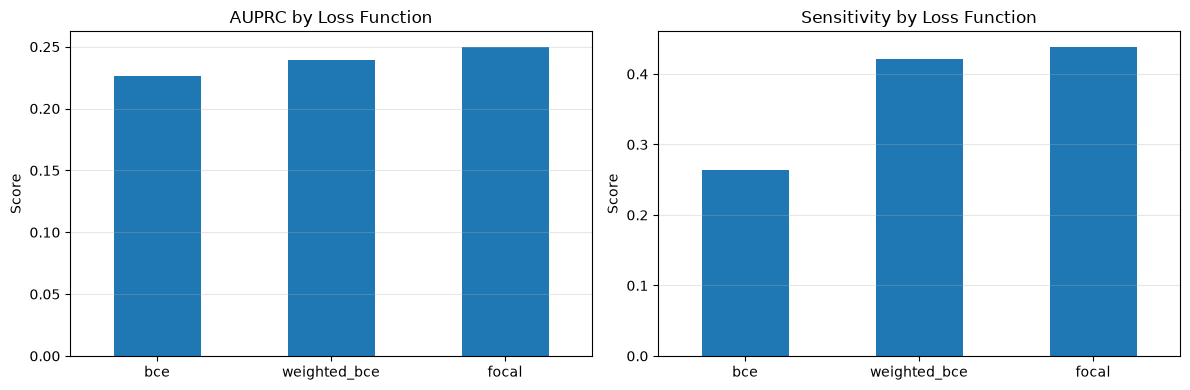

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

loss_results_df.plot(
    x="Loss",
    y="AUPRC",
    kind="bar",
    legend=False,
    ax=axes[0],
    title="AUPRC by Loss Function"
)

loss_results_df.plot(
    x="Loss",
    y="Sensitivity",
    kind="bar",
    legend=False,
    ax=axes[1],
    title="Sensitivity by Loss Function"
)

for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [21]:
loss_results_df.to_csv(
    RESULTS_DIR / "loss_ablation_results.csv",
    index=False
)

print("Results saved.")

Results saved.


## 4.3 Image Resolution Ablation

The effect of image resolution is evaluated by comparing ResNet50
classifiers trained on 224×224 and 512×512 mammograms.

Architecture, loss function, optimizer, learning rate, data partitions,
and effective batch size are kept consistent. Gradient accumulation
and mixed precision are used to accommodate the higher resolution.

In [22]:
RESOLUTIONS = [224, 512]

EFFECTIVE_BATCH_SIZE = 8
RESOLUTION_EPOCHS = 10
RESOLUTION_LR = 1e-4

PHYSICAL_BATCH_SIZES = {
    224: 8,
    512: 2
}

In [23]:
def create_resolution_loaders(image_size):

    transform = transforms.Compose([
        ResizeWithPadding(image_size),
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    train_dataset = MammographyDataset(
        train_df,
        view="CC",
        transform=transform
    )

    val_dataset = MammographyDataset(
        val_df,
        view="CC",
        transform=transform
    )

    batch_size = PHYSICAL_BATCH_SIZES[image_size]

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader

In [24]:
for resolution in RESOLUTIONS:

    train_res_loader, val_res_loader = create_resolution_loaders(
        resolution
    )

    images, labels = next(iter(train_res_loader))

    print(
        f"{resolution}×{resolution}:",
        images.shape
    )

224×224: torch.Size([8, 3, 224, 224])
512×512: torch.Size([2, 3, 512, 512])


In [25]:
def train_epoch_accumulation(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device,
    effective_batch_size=8
):
    model.train()
    total_loss = 0.0

    optimizer.zero_grad(set_to_none=True)

    accumulated = 0
    total_samples = len(loader.dataset)

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device).unsqueeze(1)

        batch_size = images.size(0)

        with torch.autocast(
            device_type=device.type,
            enabled=(device.type == "cuda")
        ):
            logits = model(images)
            loss = criterion(logits, labels)

        # Weight gradients by the number of samples
        scaler.scale(loss * batch_size).backward()

        accumulated += batch_size
        total_loss += loss.item() * batch_size

        if accumulated >= effective_batch_size:
            scaler.unscale_(optimizer)

            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.div_(accumulated)

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(set_to_none=True)
            accumulated = 0

    # Handle the final incomplete accumulation group
    if accumulated > 0:
        scaler.unscale_(optimizer)

        for parameter in model.parameters():
            if parameter.grad is not None:
                parameter.grad.div_(accumulated)

        scaler.step(optimizer)
        scaler.update()

    return total_loss / total_samples

In [26]:
def run_resolution_experiment(image_size):

    set_seed(SEED)

    train_res_loader, val_res_loader = create_resolution_loaders(
        image_size
    )

    model = create_model()

    criterion = FocalLoss(
        alpha=FOCAL_ALPHA,
        gamma=FOCAL_GAMMA
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=RESOLUTION_LR
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    history = []

    for epoch in range(RESOLUTION_EPOCHS):

        train_loss = train_epoch_accumulation(
            model,
            train_res_loader,
            criterion,
            optimizer,
            scaler,
            device,
            effective_batch_size=EFFECTIVE_BATCH_SIZE
        )

        val_loss, labels, probs = evaluate(
            model,
            val_res_loader,
            criterion
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"{image_size}×{image_size} | "
            f"Epoch {epoch+1:02d}/{RESOLUTION_EPOCHS} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

    # Restore best validation checkpoint
    model.load_state_dict(best_state)

    _, labels, probs = evaluate(
        model,
        val_res_loader,
        criterion
    )

    metrics = calculate_metrics(labels, probs)

    torch.save(
        {
            "state_dict": model.state_dict(),
            "architecture": "ResNet50",
            "resolution": image_size,
            "loss": "Focal Loss",
            "focal_alpha": FOCAL_ALPHA,
            "focal_gamma": FOCAL_GAMMA,
            "best_epoch": best_epoch,
            "seed": SEED,
            "learning_rate": RESOLUTION_LR,
            "effective_batch_size": EFFECTIVE_BATCH_SIZE,
            "physical_batch_size": PHYSICAL_BATCH_SIZES[image_size],
            "optimizer": "Adam",
            "mixed_precision": device.type == "cuda"
        },
        MODEL_DIR / f"resolution_{image_size}_best.pth"
    )

    result = {
        "Resolution": image_size,
        "Best epoch": best_epoch,
        **metrics
    }

    del model, optimizer, scaler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, pd.DataFrame(history)

In [27]:
resolution_results = []
resolution_histories = {}

for resolution in RESOLUTIONS:

    print(f"\nTraining resolution: {resolution}×{resolution}")

    result, history = run_resolution_experiment(
        resolution
    )

    resolution_results.append(result)
    resolution_histories[resolution] = history

resolution_results_df = pd.DataFrame(
    resolution_results
)

resolution_results_df.round(4)


Training resolution: 224×224
224×224 | Epoch 01/10 | Train: 0.0630 | Val: 0.0419
224×224 | Epoch 02/10 | Train: 0.0589 | Val: 0.0362
224×224 | Epoch 03/10 | Train: 0.0520 | Val: 0.0363
224×224 | Epoch 04/10 | Train: 0.0449 | Val: 0.0623
224×224 | Epoch 05/10 | Train: 0.0334 | Val: 0.0500
224×224 | Epoch 06/10 | Train: 0.0200 | Val: 0.0464
224×224 | Epoch 07/10 | Train: 0.0162 | Val: 0.0673
224×224 | Epoch 08/10 | Train: 0.0172 | Val: 0.0702
224×224 | Epoch 09/10 | Train: 0.0141 | Val: 0.0761
224×224 | Epoch 10/10 | Train: 0.0080 | Val: 0.0514

Training resolution: 512×512
512×512 | Epoch 01/10 | Train: 0.0637 | Val: 0.0467
512×512 | Epoch 02/10 | Train: 0.0593 | Val: 0.0557
512×512 | Epoch 03/10 | Train: 0.0558 | Val: 0.0391
512×512 | Epoch 04/10 | Train: 0.0503 | Val: 0.0413
512×512 | Epoch 05/10 | Train: 0.0415 | Val: 0.0346
512×512 | Epoch 06/10 | Train: 0.0347 | Val: 0.0375
512×512 | Epoch 07/10 | Train: 0.0305 | Val: 0.0447
512×512 | Epoch 08/10 | Train: 0.0183 | Val: 0.0575
512×

,Resolution,Best epoch,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,224,2,0.6781,0.1354,0.3509,0.9122,0.1724,0.2312
1,512,5,0.7858,0.3903,0.5439,0.8811,0.1925,0.2844


Increasing the input resolution from 224×224 to 512×512 improved validation AUROC (0.6781 to 0.7858), AUPRC (0.1354 to 0.3903), and sensitivity (0.3509 to 0.5439). The higher-resolution model also achieved a higher F1-score, although specificity decreased slightly.

These findings suggest that preserving more spatial detail may benefit mammographic abnormality classification.

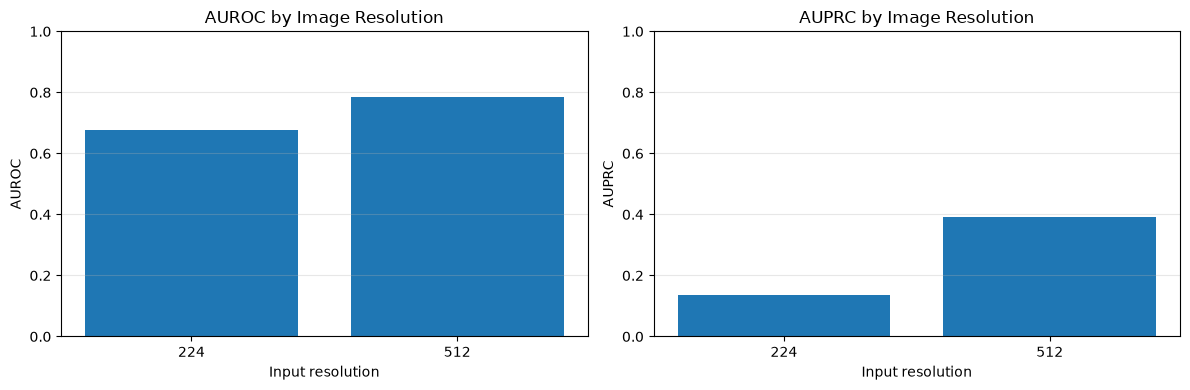

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for metric, ax in zip(
    ["AUROC", "AUPRC"],
    axes
):
    ax.bar(
        resolution_results_df["Resolution"].astype(str),
        resolution_results_df[metric]
    )

    ax.set_title(f"{metric} by Image Resolution")
    ax.set_xlabel("Input resolution")
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

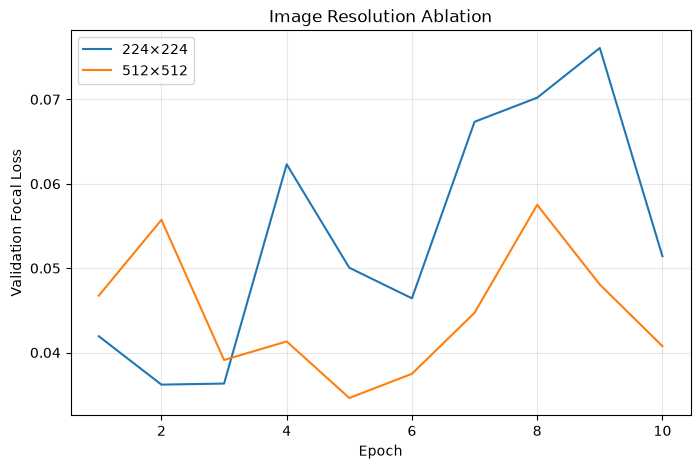

In [29]:
plt.figure(figsize=(8, 5))

for resolution in RESOLUTIONS:

    history = resolution_histories[resolution]

    plt.plot(
        history["epoch"],
        history["val_loss"],
        label=f"{resolution}×{resolution}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Focal Loss")
plt.title("Image Resolution Ablation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Both configurations showed decreasing training loss, while validation loss fluctuated during later epochs, suggesting overfitting. The best checkpoints were selected at epochs 2 and 5 for the 224×224 and 512×512 configurations, respectively.

Although both configurations used the same effective batch size, their physical batch sizes differed due to GPU memory constraints. This may affect BatchNorm statistics and introduces a potential confounding factor. Repeated experiments with a more closely controlled training configuration are needed to isolate the effect of image resolution.

In [30]:
resolution_results_df.to_csv(
    RESULTS_DIR / "resolution_ablation_results.csv",
    index=False
)

for resolution, history in resolution_histories.items():
    history.to_csv(
        RESULTS_DIR / f"resolution_{resolution}_history.csv",
        index=False
    )

print("Resolution experiments saved.")

Resolution experiments saved.


## 4.4 Data Augmentation Ablation

This experiment evaluates whether moderate data augmentation improves the generalization of a ResNet50 mammography classifier.
Two configurations are compared: training without augmentation and training with random geometric transformations. Both use 512×512 images, focal loss, identical data partitions, and the same optimization settings. Augmentation is applied only to the training images.

In [31]:
AUG_IMAGE_SIZE = 512

base_transform = transforms.Compose([
    ResizeWithPadding(AUG_IMAGE_SIZE),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

augmentation_transform = transforms.Compose([
    ResizeWithPadding(AUG_IMAGE_SIZE),

    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05),
        interpolation=transforms.InterpolationMode.BILINEAR,
        fill=0
    ),

    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

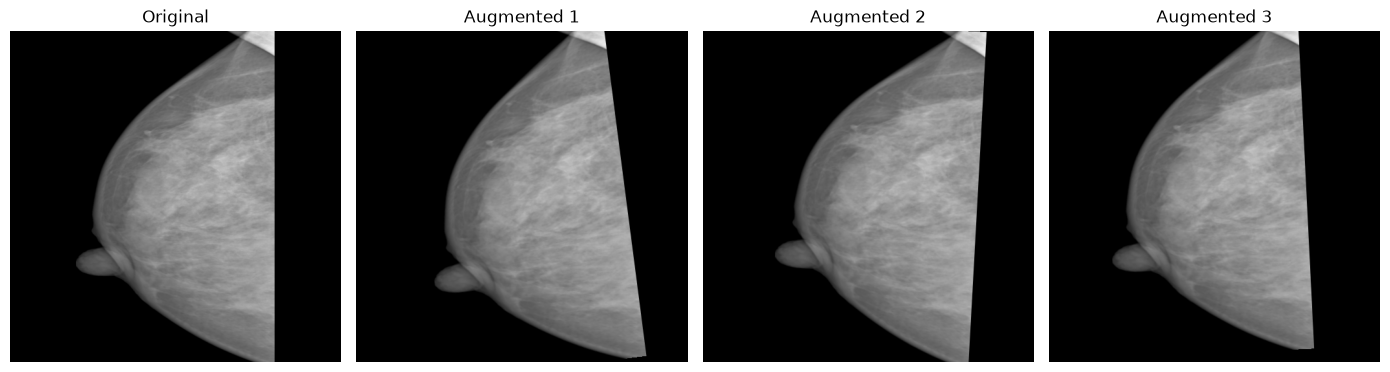

In [32]:
sample_path = train_df.iloc[0]["CC_path"]

with Image.open(sample_path) as img:
    sample_image = img.convert("RGB")

preview_transform = transforms.Compose([
    ResizeWithPadding(512),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05),
        interpolation=transforms.InterpolationMode.BILINEAR,
        fill=0
    )
])

fig, axes = plt.subplots(1, 4, figsize=(14, 5))

axes[0].imshow(
    ResizeWithPadding(512)(sample_image),
    cmap="gray"
)
axes[0].set_title("Original")

for i in range(1, 4):
    augmented = preview_transform(sample_image)

    axes[i].imshow(augmented, cmap="gray")
    axes[i].set_title(f"Augmented {i}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Moderate affine transformations were applied to introduce geometric variability while preserving the overall breast anatomy. Representative augmented images were visualized to assess potential cropping and distortion. However, subtle anatomical changes may still affect diagnostic information.

In [33]:
AUG_BATCH_SIZE = 2
AUG_EFFECTIVE_BATCH_SIZE = 8
AUG_EPOCHS = 10
AUG_LR = 1e-4


def create_augmentation_loaders(use_augmentation=False):

    train_transform = (
        augmentation_transform
        if use_augmentation
        else base_transform
    )

    train_dataset = MammographyDataset(
        train_df,
        view="CC",
        transform=train_transform
    )

    val_dataset = MammographyDataset(
        val_df,
        view="CC",
        transform=base_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=AUG_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=AUG_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    return train_loader, val_loader

In [34]:
def run_augmentation_experiment(use_augmentation):

    set_seed(SEED)

    train_aug_loader, val_aug_loader = (
        create_augmentation_loaders(use_augmentation)
    )

    model = create_model()

    criterion = FocalLoss(
        alpha=FOCAL_ALPHA,
        gamma=FOCAL_GAMMA
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=AUG_LR
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None

    history = []

    experiment_name = (
        "augmentation"
        if use_augmentation
        else "no_augmentation"
    )

    for epoch in range(AUG_EPOCHS):

        train_loss = train_epoch_accumulation(
            model,
            train_aug_loader,
            criterion,
            optimizer,
            scaler,
            device,
            effective_batch_size=AUG_EFFECTIVE_BATCH_SIZE
        )

        val_loss, _, _ = evaluate(
            model,
            val_aug_loader,
            criterion
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"{experiment_name} | "
            f"Epoch {epoch+1:02d}/{AUG_EPOCHS} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

    model.load_state_dict(best_state)

    _, labels, probs = evaluate(
        model,
        val_aug_loader,
        criterion
    )

    metrics = calculate_metrics(labels, probs)

    torch.save(
        {
            "state_dict": model.state_dict(),
            "architecture": "ResNet50",
            "view": "CC",
            "augmentation": use_augmentation,
            "augmentation_config": (
                "RandomAffine(rotation=10, translation=0.05, scale=0.95-1.05)"
                if use_augmentation
                else "None"
            ),
            "resolution": AUG_IMAGE_SIZE,
            "loss": "Focal Loss",
            "focal_alpha": FOCAL_ALPHA,
            "focal_gamma": FOCAL_GAMMA,
            "best_epoch": best_epoch,
            "epochs": AUG_EPOCHS,
            "seed": SEED,
            "learning_rate": AUG_LR,
            "physical_batch_size": AUG_BATCH_SIZE,
            "effective_batch_size": AUG_EFFECTIVE_BATCH_SIZE,
            "optimizer": "Adam"
        },
        MODEL_DIR / f"augmentation_{experiment_name}_best.pth"
    )

    result = {
        "Configuration": (
            "With augmentation"
            if use_augmentation
            else "Without augmentation"
        ),
        "Best epoch": best_epoch,
        **metrics
    }

    del model, optimizer, scaler

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, pd.DataFrame(history)

In [35]:
augmentation_results = []
augmentation_histories = {}

for use_augmentation in [False, True]:

    name = (
        "With augmentation"
        if use_augmentation
        else "Without augmentation"
    )

    print(f"\nTraining: {name}")

    result, history = run_augmentation_experiment(
        use_augmentation
    )

    augmentation_results.append(result)
    augmentation_histories[name] = history

augmentation_results_df = pd.DataFrame(
    augmentation_results
)

augmentation_results_df.round(4)


Training: Without augmentation
no_augmentation | Epoch 01/10 | Train: 0.0637 | Val: 0.0467
no_augmentation | Epoch 02/10 | Train: 0.0593 | Val: 0.0557
no_augmentation | Epoch 03/10 | Train: 0.0558 | Val: 0.0391
no_augmentation | Epoch 04/10 | Train: 0.0503 | Val: 0.0413
no_augmentation | Epoch 05/10 | Train: 0.0415 | Val: 0.0346
no_augmentation | Epoch 06/10 | Train: 0.0347 | Val: 0.0375
no_augmentation | Epoch 07/10 | Train: 0.0305 | Val: 0.0447
no_augmentation | Epoch 08/10 | Train: 0.0183 | Val: 0.0575
no_augmentation | Epoch 09/10 | Train: 0.0192 | Val: 0.0481
no_augmentation | Epoch 10/10 | Train: 0.0149 | Val: 0.0408

Training: With augmentation
augmentation | Epoch 01/10 | Train: 0.0637 | Val: 0.0472
augmentation | Epoch 02/10 | Train: 0.0616 | Val: 0.0494
augmentation | Epoch 03/10 | Train: 0.0590 | Val: 0.0459
augmentation | Epoch 04/10 | Train: 0.0562 | Val: 0.0415
augmentation | Epoch 05/10 | Train: 0.0536 | Val: 0.0480
augmentation | Epoch 06/10 | Train: 0.0516 | Val: 0.05

,Configuration,Best epoch,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,Without augmentation,5,0.7858,0.3903,0.5439,0.8811,0.1925,0.2844
1,With augmentation,7,0.7918,0.2939,0.5789,0.9186,0.2705,0.3687


Data augmentation improved validation AUROC from 0.7858 to 0.7918, sensitivity from 0.5439 to 0.5789, specificity from 0.8811 to 0.9186, and F1-score from 0.2844 to 0.3687. However, AUPRC decreased from 0.3903 to 0.2939.

The findings suggest that moderate geometric augmentation can improve classification at the default threshold of 0.5, but does not necessarily improve the precision–recall trade-off across all thresholds. Further repeated experiments are needed to assess the stability of these differences.

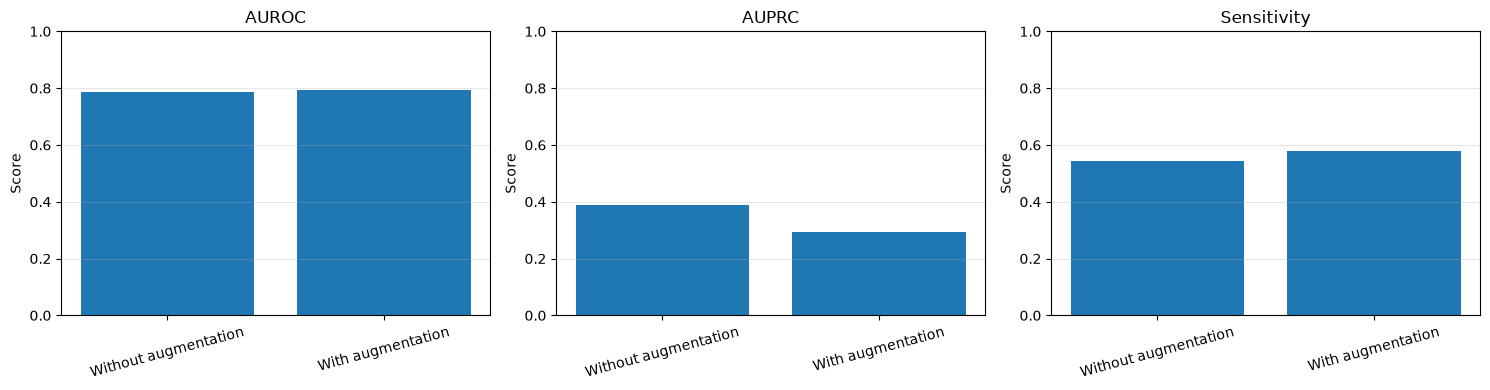

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics_to_plot = [
    "AUROC",
    "AUPRC",
    "Sensitivity"
]

for ax, metric in zip(axes, metrics_to_plot):

    ax.bar(
        augmentation_results_df["Configuration"],
        augmentation_results_df[metric]
    )

    ax.set_title(metric)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=15)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

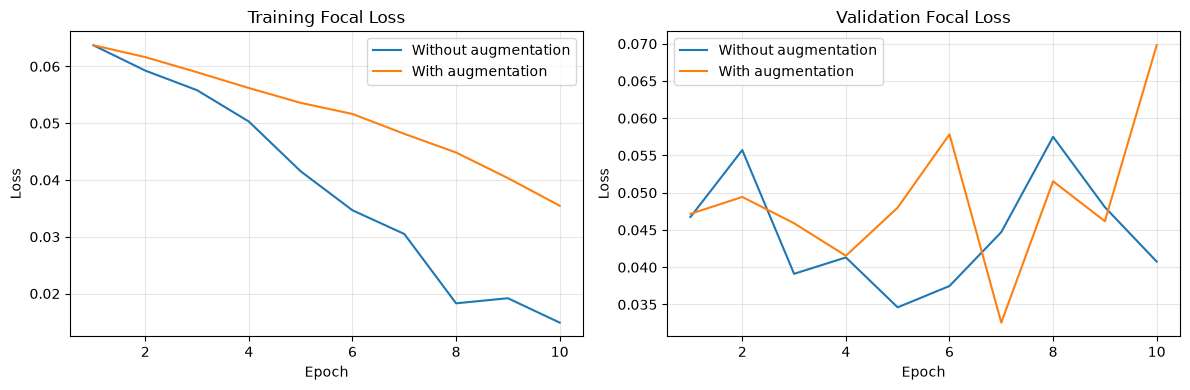

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in augmentation_histories.items():

    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["val_loss"],
        label=name
    )

axes[0].set_title("Training Focal Loss")
axes[1].set_title("Validation Focal Loss")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Both models showed decreasing training loss, while validation loss fluctuated across epochs. The augmented model achieved its lowest validation loss at epoch 7, compared with epoch 5 for the baseline. Augmentation appeared to delay overfitting, although the validation curves do not establish a consistent improvement across all metrics.

In [38]:
augmentation_results_df.to_csv(
    RESULTS_DIR / "augmentation_ablation_results.csv",
    index=False
)

for name, history in augmentation_histories.items():

    filename = name.lower().replace(" ", "_")

    history.to_csv(
        RESULTS_DIR / f"{filename}_history.csv",
        index=False
    )

print("Augmentation ablation results saved.")

Augmentation ablation results saved.


## 4.5 Final Ablation Summary

This section summarizes the effects of loss functions, image resolution, and data augmentation on mammography classification performance.

The ablation experiments were conducted using an ImageNet-pretrained ResNet50 classifier on CC mammograms. Validation AUROC, AUPRC, sensitivity, specificity, precision, and F1-score are used to assess the impact of each modification.

The experiments are interpreted within their respective controlled comparisons rather than as a single fully factorial study.

In [43]:
loss_results = pd.read_csv(
    RESULTS_DIR / "loss_ablation_results.csv"
)

resolution_results = pd.read_csv(
    RESULTS_DIR / "resolution_ablation_results.csv"
)

augmentation_results = pd.read_csv(
    RESULTS_DIR / "augmentation_ablation_results.csv"
)

display(loss_results)
display(resolution_results)
display(augmentation_results)

,Loss,Best epoch,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,bce,3,0.731577,0.226174,0.263158,0.968893,0.306122,0.283019
1,weighted_bce,3,0.732139,0.239379,0.421053,0.900274,0.180451,0.252632
2,focal,6,0.741047,0.249948,0.438596,0.911253,0.204918,0.279330


,Resolution,Best epoch,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,224,2,0.678143,0.135381,0.350877,0.912168,0.172414,0.231214
1,512,5,0.785798,0.390310,0.543860,0.881061,0.192547,0.284404


,Configuration,Best epoch,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,Without augmentation,5,0.785798,0.390310,0.543860,0.881061,0.192547,0.284404
1,With augmentation,7,0.791833,0.293949,0.578947,0.918573,0.270492,0.368715


In [44]:
loss_summary = loss_results.copy()

loss_summary["Experiment"] = "Loss function"
loss_summary["Configuration"] = loss_summary["Loss"]
loss_summary["Resolution"] = 224
loss_summary["Augmentation"] = "None"

resolution_summary = resolution_results.copy()

resolution_summary["Experiment"] = "Image resolution"
resolution_summary["Configuration"] = (
    resolution_summary["Resolution"].astype(str) + "x"
    + resolution_summary["Resolution"].astype(str)
)
resolution_summary["Augmentation"] = "None"

augmentation_summary = augmentation_results.copy()

augmentation_summary["Experiment"] = "Data augmentation"
augmentation_summary["Resolution"] = 512
augmentation_summary["Augmentation"] = (
    augmentation_summary["Configuration"]
)

metrics_columns = [
    "AUROC", "AUPRC", "Sensitivity",
    "Specificity", "Precision", "F1"
]

columns = [
    "Experiment", "Configuration",
    "Resolution", "Augmentation",
    "Best epoch", *metrics_columns
]

ablation_summary = pd.concat(
    [
        loss_summary[columns],
        resolution_summary[columns],
        augmentation_summary[columns]
    ],
    ignore_index=True
)

display(ablation_summary.round(4))

,Experiment,Configuration,Resolution,Augmentation,Best epoch,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,Loss function,bce,224,None,3,0.7316,0.2262,0.2632,0.9689,0.3061,0.2830
1,Loss function,weighted_bce,224,None,3,0.7321,0.2394,0.4211,0.9003,0.1805,0.2526
2,Loss function,focal,224,None,6,0.7410,0.2499,0.4386,0.9113,0.2049,0.2793
3,Image resolution,224x224,224,None,2,0.6781,0.1354,0.3509,0.9122,0.1724,0.2312
4,Image resolution,512x512,512,None,5,0.7858,0.3903,0.5439,0.8811,0.1925,0.2844
5,Data augmentation,Without augmentation,512,Without augmentation,5,0.7858,0.3903,0.5439,0.8811,0.1925,0.2844
6,Data augmentation,With augmentation,512,With augmentation,7,0.7918,0.2939,0.5789,0.9186,0.2705,0.3687


In [45]:
def compare_configs(df, baseline_filter, modified_filter, metrics):
    baseline = df.loc[baseline_filter].iloc[0]
    modified = df.loc[modified_filter].iloc[0]

    return {
        metric: modified[metric] - baseline[metric]
        for metric in metrics
    }


delta_loss = compare_configs(
    loss_results,
    loss_results["Loss"] == "bce",
    loss_results["Loss"] == "focal",
    metrics_columns
)

delta_resolution = compare_configs(
    resolution_results,
    resolution_results["Resolution"] == 224,
    resolution_results["Resolution"] == 512,
    metrics_columns
)

delta_augmentation = compare_configs(
    augmentation_results,
    augmentation_results["Configuration"] == "Without augmentation",
    augmentation_results["Configuration"] == "With augmentation",
    metrics_columns
)

delta_summary = pd.DataFrame({
    "BCE → Focal Loss": delta_loss,
    "224 → 512": delta_resolution,
    "Without → With augmentation": delta_augmentation
}).T

display(delta_summary.round(4))

,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
BCE → Focal Loss,0.0095,0.0238,0.1754,-0.0576,-0.1012,-0.0037
224 → 512,0.1077,0.2549,0.1930,-0.0311,0.0201,0.0532
Without → With augmentation,0.0060,-0.0964,0.0351,0.0375,0.0779,0.0843


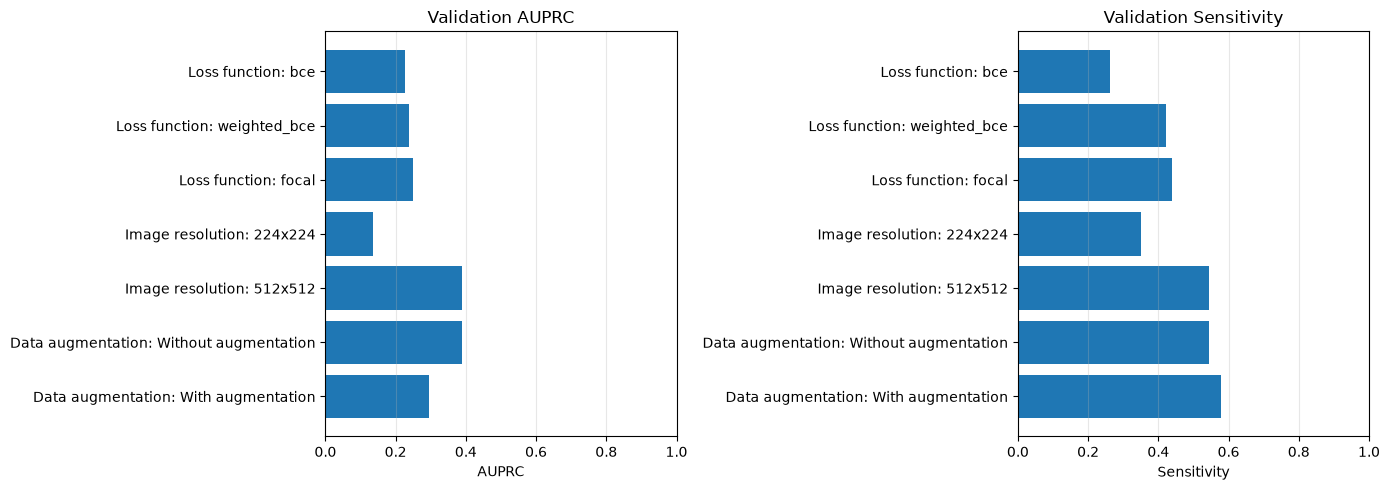

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(
    axes,
    ["AUPRC", "Sensitivity"]
):
    labels = (
        ablation_summary["Experiment"] + ": "
        + ablation_summary["Configuration"]
    )

    ax.barh(labels, ablation_summary[metric])
    ax.set_title(f"Validation {metric}")
    ax.set_xlabel(metric)
    ax.set_xlim(0, 1)
    ax.grid(axis="x", alpha=0.3)

axes[0].invert_yaxis()
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

### Discussion

The loss function ablation showed that focal loss achieved higher AUROC, AUPRC, and sensitivity than standard BCE, although standard BCE retained a slightly higher F1-score.

Increasing image resolution from 224×224 to 512×512 was associated with substantial improvements in AUROC, AUPRC, and sensitivity. This suggests that higher spatial resolution may help preserve diagnostically relevant image information.

Data augmentation improved AUROC, sensitivity, specificity, and F1-score, but reduced AUPRC. Therefore, augmentation did not consistently improve performance across all evaluation metrics.

The findings highlight the importance of evaluating multiple metrics rather than relying on classification accuracy or a single performance measure.

### Limitations

All ablation experiments were initially conducted using a single random seed (42). Consequently, the stability of the observed improvements across independent training runs has not yet been established.

The resolution experiment used different physical batch sizes, potentially affecting BatchNorm statistics despite identical effective batch sizes.

Furthermore, the validation set contained relatively few positive examples, making performance estimates sensitive to individual predictions. The experiments used BI-RADS-derived suspicion labels rather than histopathologically confirmed cancer outcomes.

These limitations should be considered when interpreting the results. Additional controlled repetitions and final evaluation on the held-out test set are needed.

In [1]:
ablation_summary.to_csv(
    RESULTS_DIR / "final_ablation_summary.csv",
    index=False
)

delta_summary.to_csv(
    RESULTS_DIR / "ablation_metric_changes.csv"
)

print("Final ablation summary saved.")

NameError: name 'ablation_summary' is not defined

## 4.6 Conclusion

The ablation study demonstrated that loss function selection, image resolution, and data augmentation can substantially influence mammography classification performance.

Higher input resolution produced the strongest observed improvement in validation AUPRC, while focal loss increased sensitivity compared with standard BCE. Data augmentation improved several threshold-dependent metrics but reduced AUPRC.

The results provide a basis for selecting candidate configurations for subsequent experiments. Final model selection requires repeated training runs and evaluation of both single-view and multi-view approaches.